Q2. Perform image zooming and shrinking using different interpolation techniques:

    - Nearest-neighbor interpolation
    - Bilinear interpolation
    - Bicubic interpolation

    Perform:
        - 2× zooming
        - 4× zooming
        - 1/2 shrinking
        - 1/4 shrinking

Compare the visual quality of the resulting images.

In [12]:
# Import libraries
import cv2
import matplotlib.pyplot as plt

Original image size: 2550 x 3300


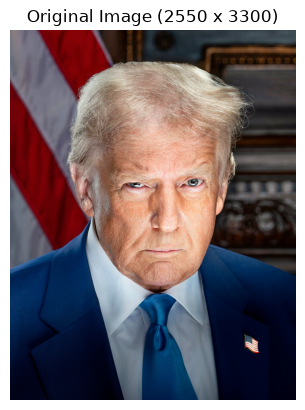

In [13]:
# Read the image in colour
image = cv2.imread('../input.jpg', cv2.IMREAD_COLOR)

if image is None:
    raise FileNotFoundError('Image not found. Check the image filename and path.')

height, width = image.shape[:2]
print('Original image size:', width, 'x', height)

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f'Original Image ({width} x {height})')
plt.axis('off')
plt.show()

In [14]:
# Define different scaling factors
scales = [2, 4, 0.5, 0.25]

# Define interpolation techniques
interpolations = {
    'Nearest Neighbor': cv2.INTER_NEAREST,
    'Bilinear': cv2.INTER_LINEAR,
    'Bicubic': cv2.INTER_CUBIC
}

# Store the resized images
results = {}

# Perform zooming and shrinking using different interpolation techniques
for scale in scales:

    # Calculate the new image dimensions
    new_width = int(width * scale)
    new_height = int(height * scale)

    for name, method in interpolations.items():

        # Resize the original image using the current interpolation technique
        resized = cv2.resize(image, (new_width, new_height), interpolation=method)

        # Store the resulting image
        results[(scale, name)] = resized

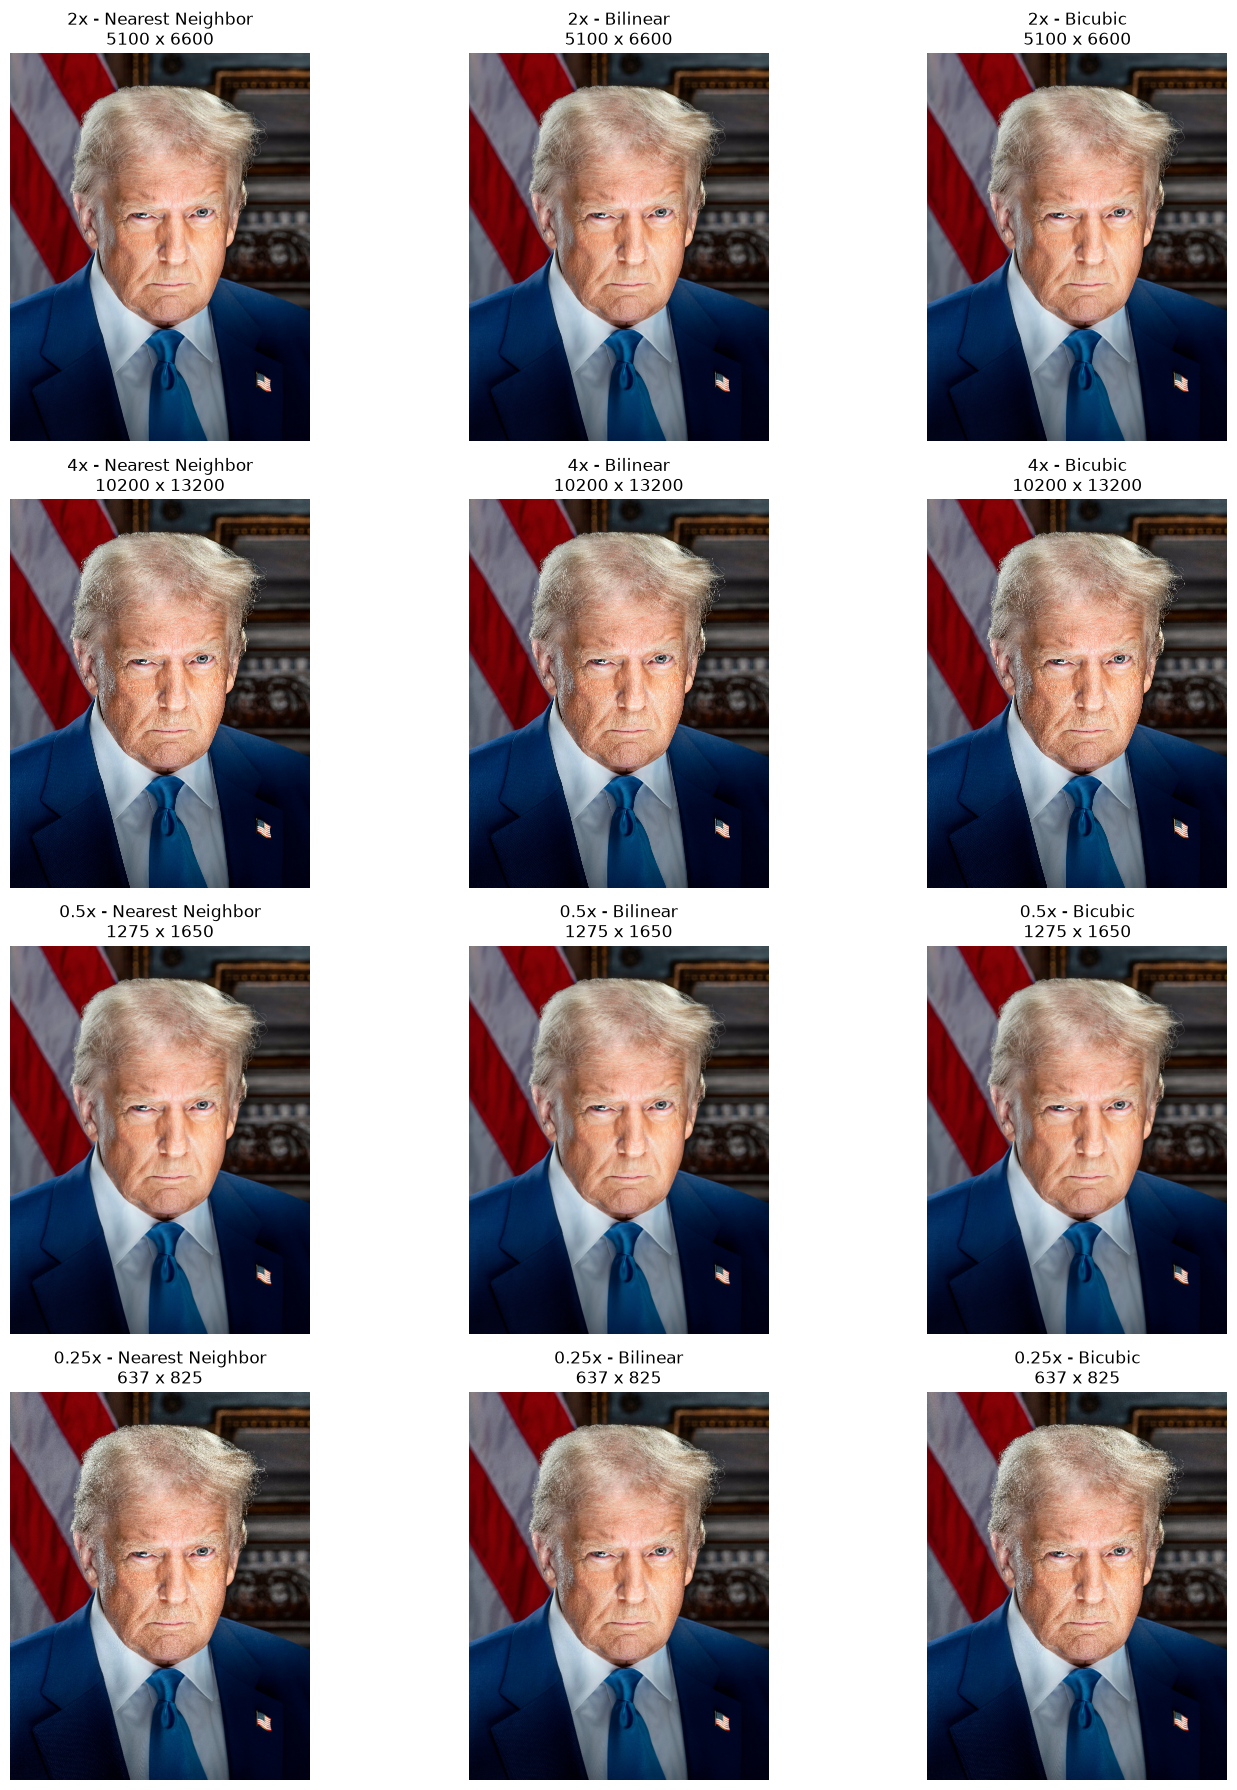

In [16]:
# Display the results using Matplotlib
plt.figure(figsize=(15, 18))

for i, scale in enumerate(scales):

    for j, name in enumerate(interpolations.keys()):

        # Get the resized image
        resized = results[(scale, name)]

        # Display the image in a subplot
        plt.subplot(4, 3, i * 3 + j + 1)

        plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))

        # Set the title
        plt.title(f'{scale}x - {name}\n{resized.shape[1]} x {resized.shape[0]}')

        plt.axis('off')

plt.tight_layout()
plt.show()